# Mask Analysis and Data Quality Audit

This notebook investigates the dataset's raw mask values and image/mask data quality using the precomputed audit report. It loads only one representative FITS image and mask for detailed visual inspection; aggregate statistics come from the audit JSON.

**Official dataset meanings** (from the benchmark documentation): raw value 0 = No relevant data; 1 = galaxy center or core; 2 = galaxy bar; 3 = galaxy arms; 4 = star. These are dataset semantics, not training IDs.

**Current project training policy:** raw value 0 is ignored using `ignore_index=255`; raw values 1-4 map respectively to contiguous training IDs 0-3. The model has four trainable classes. This policy is a project choice, distinct from the meanings assigned by the dataset documentation.


## 1. Paths, imports, and audit report

Run this notebook with the repository as the working directory, or from one of its subdirectories. Paths are resolved relative to the repository root. The report and raw FITS files are opened read-only; this notebook does not update either.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from astropy.io import fits
from IPython.display import display, Markdown

# Locate the repository root without embedding machine-specific absolute paths.
ROOT_CANDIDATES = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (candidate for candidate in ROOT_CANDIDATES
     if (candidate / 'dataset' / 'raw').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Could not find the project root (expected a dataset/raw directory) '
        'above the current working directory.'
    )

RAW_DIR = PROJECT_ROOT / 'dataset' / 'raw'
AUDIT_PATH = PROJECT_ROOT / 'dataset' / 'metadata' / 'mask_audit.json'
if not RAW_DIR.is_dir():
    raise FileNotFoundError(f'Raw dataset directory is missing: {RAW_DIR}')
if not AUDIT_PATH.is_file():
    raise FileNotFoundError(f'FITS audit report is missing: {AUDIT_PATH}')

with AUDIT_PATH.open('r', encoding='utf-8') as report_file:
    audit = json.load(report_file)

REQUIRED_SECTIONS = {
    'audit_summary', 'pairing', 'image_statistics', 'mask_statistics',
    'dimension_checks', 'data_quality', 'representative_sample', 'errors',
}
missing_sections = REQUIRED_SECTIONS.difference(audit)
if missing_sections:
    raise ValueError(f'Audit report is missing sections: {sorted(missing_sections)}')
print(f'Project root: {PROJECT_ROOT}')
print(f'Audit report: {AUDIT_PATH}')
print(f'Raw dataset directory: {RAW_DIR}')

Project root: c:\Users\souro\Desktop\galaxy-segmentation
Audit report: c:\Users\souro\Desktop\galaxy-segmentation\dataset\metadata\mask_audit.json
Raw dataset directory: c:\Users\souro\Desktop\galaxy-segmentation\dataset\raw


## 2. Dataset and pairing summary

The counts below are read from the saved audit report. A filename ID present on both sides is a unique pair only when each side has exactly one file for that ID; duplicate-ID candidate combinations are kept separate as ambiguous.

In [2]:
summary = audit['audit_summary']
pairing = audit['pairing']
errors = audit['errors']
image_read_errors = [e for e in errors.get('file_errors', [])
                      if 'imagedata_' in e.get('path', '').lower()]
mask_read_errors = [e for e in errors.get('file_errors', [])
                     if 'mask_' in e.get('path', '').lower()]

summary_rows = [
    ('Image FITS files', summary['image_file_count']),
    ('Mask FITS files', summary['mask_file_count']),
    ('Unique matched image-mask pairs', len(pairing['matched_pairs'])),
    ('Unmatched image IDs', len(pairing['unmatched_images'])),
    ('Unmatched mask IDs', len(pairing['unmatched_masks'])),
    ('Duplicate image IDs', len(pairing['duplicate_image_ids'])),
    ('Duplicate mask IDs', len(pairing['duplicate_mask_ids'])),
    ('Ambiguous candidate combinations', len(pairing.get('ambiguous_candidate_combinations', []))),
    ('Unexpected FITS filenames', len(summary['unexpected_fits_filenames'])),
    ('Image file read errors', len(image_read_errors)),
    ('Mask file read errors', len(mask_read_errors)),
    ('HDU inspection errors', len(errors.get('hdu_errors', []))),
]
display(pd.DataFrame(summary_rows, columns=['Finding', 'Count']))

,Finding,Count
0,Image FITS files,2879
1,Mask FITS files,2908
2,Unique matched image-mask pairs,2879
3,Unmatched image IDs,0
4,Unmatched mask IDs,29
5,Duplicate image IDs,0
6,Duplicate mask IDs,0
7,Ambiguous candidate combinations,0
8,Unexpected FITS filenames,0
9,Image file read errors,0


## 3. Raw mask-value distribution

These are observed numeric values only. The report gives percentages against both all mask pixels and finite mask pixels; non-finite pixels are counted separately and are not treated as values. The chart labels use the raw values exactly as recorded.

,value,pixel_count,percentage_of_total_pixels,percentage_of_finite_pixels,mask_count
0,0.0,103962425,82.633344,82.633344,2907
1,1.0,24812,0.019722,0.019722,2902
2,2.0,5242726,4.167121,4.167121,2520
3,3.0,16556365,13.159637,13.159637,2638
4,4.0,25384,0.020176,0.020176,1866


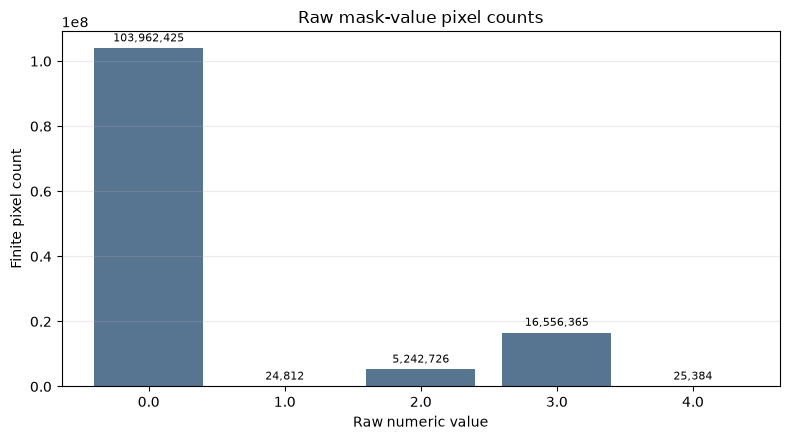

In [3]:
mask_stats = audit['mask_statistics']
value_rows = mask_stats['raw_value_frequencies']
value_table = pd.DataFrame(value_rows)
if value_table.empty:
    display(Markdown('No finite raw mask values were available in the audit report.'))
else:
    display(value_table[[
        'value', 'pixel_count', 'percentage_of_total_pixels',
        'percentage_of_finite_pixels', 'mask_count'
    ]])
    fig, ax = plt.subplots(figsize=(8, 4.5))
    labels = [str(value) for value in value_table['value']]
    bars = ax.bar(labels, value_table['pixel_count'], color='#577590')
    ax.set_title('Raw mask-value pixel counts')
    ax.set_xlabel('Raw numeric value')
    ax.set_ylabel('Finite pixel count')
    ax.grid(axis='y', alpha=0.25)
    ax.bar_label(bars, labels=[f'{int(v):,}' for v in value_table['pixel_count']], padding=3, fontsize=8)
    fig.tight_layout()
    plt.show()

## 4. Image and mask data-quality findings

Non-finite image pixels can affect numerical summaries, normalization, and downstream operations that expect finite inputs. The audit findings below identify where they occur; this notebook does not replace, filter, or repair them. The mask findings are shown separately. The official benchmark defines raw values 0-4 as No relevant data, galaxy center or core, galaxy bar, galaxy arms, and star, respectively. Under current project training policy, raw 0 is ignored with `ignore_index=255`, while raw 1-4 map to four trainable IDs 0-3. Dataset meanings and project training treatment are separate.


In [5]:
quality = audit['data_quality']
image_nonfinite = quality['image_non_finite_hdus']
image_nonfinite_files = sorted({item['path'] for item in image_nonfinite})
image_nonfinite_pixels = sum(item['non_finite_count'] for item in image_nonfinite)
print(
    f"Image non-finite findings: {len(image_nonfinite_files):,} files, "
    f"{len(image_nonfinite):,} HDUs, {image_nonfinite_pixels:,} pixels."
)
if image_nonfinite:
    display(pd.DataFrame(image_nonfinite).sort_values(['path', 'hdu_index']).reset_index(drop=True))

mask_quality_rows = [
    {'Finding': 'Mask HDUs with non-finite pixels', 'Count': len(quality['mask_non_finite_hdus'])},
    {'Finding': 'Mask HDUs with non-integer-like finite values', 'Count': len(quality['mask_non_integer_like_hdus'])},
    {'Finding': 'Mask HDUs with missing data', 'Count': len(quality['mask_missing_data_hdus'])},
    {'Finding': 'Mask HDU inspection errors', 'Count': len(quality.get('hdu_inspection_errors', []))},
]
display(pd.DataFrame(mask_quality_rows))
mask_stats[['total_pixel_count', 'finite_pixel_count', 'non_finite_pixel_count',
            'unrepresented_finite_value_pixel_count']]

Image non-finite findings: 125 files, 160 HDUs, 56,841 pixels.


,path,hdu_index,non_finite_count
0,dataset/raw/imagedata_1-101266.fits,0,1
1,dataset/raw/imagedata_1-103045.fits,0,14
2,dataset/raw/imagedata_1-103458.fits,0,1280
3,dataset/raw/imagedata_1-11594.fits,1,238
4,dataset/raw/imagedata_1-117115.fits,0,20
...,...,...,...
155,dataset/raw/imagedata_1-71974.fits,1,2
156,dataset/raw/imagedata_1-73464.fits,0,127
157,dataset/raw/imagedata_1-78013.fits,3,96
158,dataset/raw/imagedata_1-81318.fits,0,172


,Finding,Count
0,Mask HDUs with non-finite pixels,0
1,Mask HDUs with non-integer-like finite values,0
2,Mask HDUs with missing data,0
3,Mask HDU inspection errors,0


TypeError: unhashable type: 'list'

## 5. Representative sample: `1-100523`

This section opens only the representative image and mask in FITS read-only mode. It displays every data-bearing image HDU and the corresponding raw mask. For image display only, non-finite pixels are masked and each image is scaled using its own finite 1st and 99th percentiles; the loaded source arrays are not changed. The mask uses distinct colors and colorbar labels containing both each observed raw value and its official benchmark meaning; this display does not alter the raw mask.


,Kind,HDU index,HDU name,Shape,dtype
0,Image,0,PRIMARY,"(208, 208)",>f4
1,Image,1,,"(208, 208)",>f4
2,Image,2,,"(208, 208)",>f4
3,Image,3,,"(208, 208)",>f4
4,Image,4,,"(208, 208)",>f4
5,Mask,0,PRIMARY,"(208, 208)",>f8


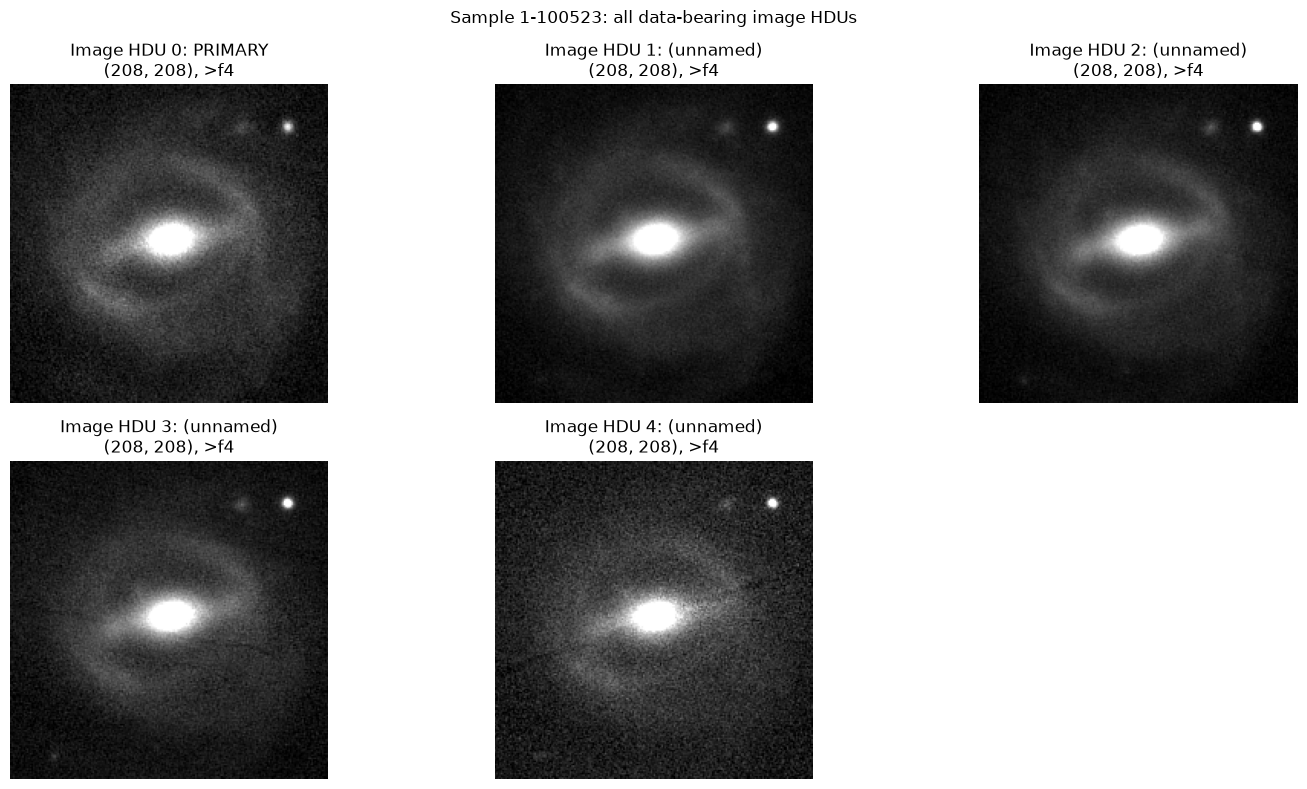

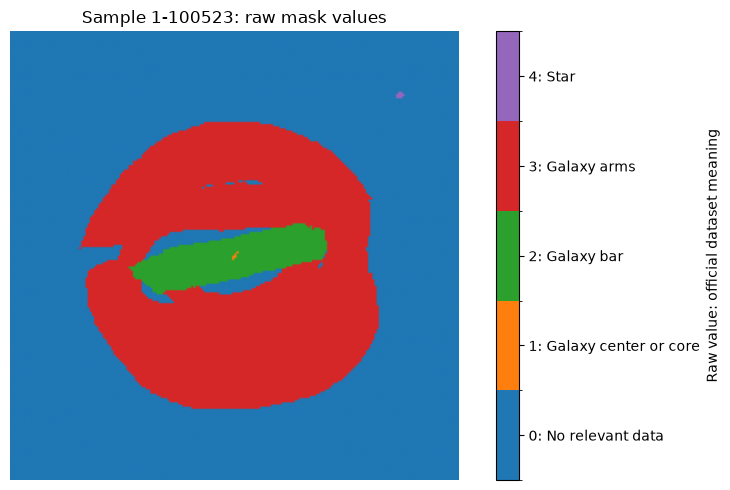

In [6]:
REPRESENTATIVE_ID = '1-100523'
representative = audit['representative_sample']
image_record = representative.get('image')
mask_record = representative.get('mask')
assert image_record is not None and mask_record is not None, (
    f'Representative sample {REPRESENTATIVE_ID} is not present in the audit report.'
)

def report_path_to_local(path_text):
    path = Path(path_text)
    return path if path.is_absolute() else PROJECT_ROOT / path

image_path = report_path_to_local(image_record['path'])
mask_path = report_path_to_local(mask_record['path'])
if not image_path.is_file():
    raise FileNotFoundError(f'Representative image is missing: {image_path}')
if not mask_path.is_file():
    raise FileNotFoundError(f'Representative mask is missing: {mask_path}')

with fits.open(image_path, mode='readonly', memmap=True) as image_hdul:
    image_arrays = [
        (index, hdu.name, np.array(hdu.data, copy=True))
        for index, hdu in enumerate(image_hdul) if hdu.data is not None
    ]
with fits.open(mask_path, mode='readonly', memmap=True) as mask_hdul:
    mask_data_hdus = [(index, hdu.name, np.array(hdu.data, copy=True))
                      for index, hdu in enumerate(mask_hdul) if hdu.data is not None]
if not image_arrays:
    raise ValueError(f'No data-bearing image HDU in {image_path}')
if not mask_data_hdus:
    raise ValueError(f'No data-bearing mask HDU in {mask_path}')
mask_hdu_index, mask_hdu_name, raw_mask = mask_data_hdus[0]

assert raw_mask.ndim >= 2, f'Expected spatial mask dimensions, got {raw_mask.shape}'
for hdu_index, hdu_name, image_array in image_arrays:
    assert image_array.ndim >= 2, (f'Image HDU {hdu_index} has no 2D spatial plane: '
                                  f'{image_array.shape}')
    assert image_array.shape[-2:] == raw_mask.shape[-2:], (
        f'Spatial mismatch: image HDU {hdu_index} {image_array.shape} vs mask {raw_mask.shape}'
    )

metadata_rows = [
    {'Kind': 'Image', 'HDU index': i, 'HDU name': name, 'Shape': arr.shape, 'dtype': str(arr.dtype)}
    for i, name, arr in image_arrays
] + [{
    'Kind': 'Mask', 'HDU index': mask_hdu_index, 'HDU name': mask_hdu_name,
    'Shape': raw_mask.shape, 'dtype': str(raw_mask.dtype)
}]
display(pd.DataFrame(metadata_rows))

def display_limits(array):
    finite = array[np.isfinite(array)]
    if finite.size == 0:
        return None, None
    low, high = np.percentile(finite, [1, 99])
    if low == high:
        high = np.nextafter(high, np.inf)
    return low, high

n_images = len(image_arrays)
ncols = min(3, n_images)
nrows = (n_images + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
for ax, (hdu_index, hdu_name, image_array) in zip(axes.flat, image_arrays):
    vmin, vmax = display_limits(image_array)
    if vmin is None:
        ax.text(0.5, 0.5, 'No finite pixels', ha='center', va='center', transform=ax.transAxes)
    else:
        shown = np.ma.masked_invalid(image_array)
        ax.imshow(shown, origin='lower', cmap='gray', vmin=vmin, vmax=vmax)
    ax.set_title(f'Image HDU {hdu_index}: {hdu_name or "(unnamed)"}\n{image_array.shape}, {image_array.dtype}')
    ax.set_axis_off()
for ax in axes.flat[n_images:]:
    ax.set_visible(False)
fig.suptitle(f'Sample {REPRESENTATIVE_ID}: all data-bearing image HDUs')
fig.tight_layout()
plt.show()

raw_values = np.unique(raw_mask[np.isfinite(raw_mask)])
if raw_values.size == 0:
    raise ValueError('Representative mask contains no finite raw values to display.')
# Palette indices are display-only; the source mask retains its raw values.
mask_codes = np.full(raw_mask.shape, np.nan, dtype=float)
finite_mask = np.isfinite(raw_mask)
mask_codes[finite_mask] = np.searchsorted(raw_values, raw_mask[finite_mask])
colors = plt.get_cmap('tab10').colors[:len(raw_values)]
mask_cmap = ListedColormap(colors)
mask_cmap.set_bad(color=(0, 0, 0, 0))
mask_norm = BoundaryNorm(np.arange(len(raw_values) + 1) - 0.5, mask_cmap.N)
fig, ax = plt.subplots(figsize=(9, 5))
mask_plot = ax.imshow(np.ma.masked_invalid(mask_codes), origin='lower', cmap=mask_cmap, norm=mask_norm)
ax.set_title(f'Sample {REPRESENTATIVE_ID}: raw mask values')
ax.set_axis_off()
colorbar = fig.colorbar(mask_plot, ax=ax, ticks=np.arange(len(raw_values)))
official_category_names = {
    0.0: 'No relevant data',
    1.0: 'Galaxy center or core',
    2.0: 'Galaxy bar',
    3.0: 'Galaxy arms',
    4.0: 'Star',
}
colorbar_labels = [
    f'{value:g}: {official_category_names.get(float(value), "Undocumented raw value")}'
    for value in raw_values
]
colorbar.ax.set_yticklabels(colorbar_labels)
colorbar.set_label('Raw value: official dataset meaning')
fig.tight_layout()
plt.show()

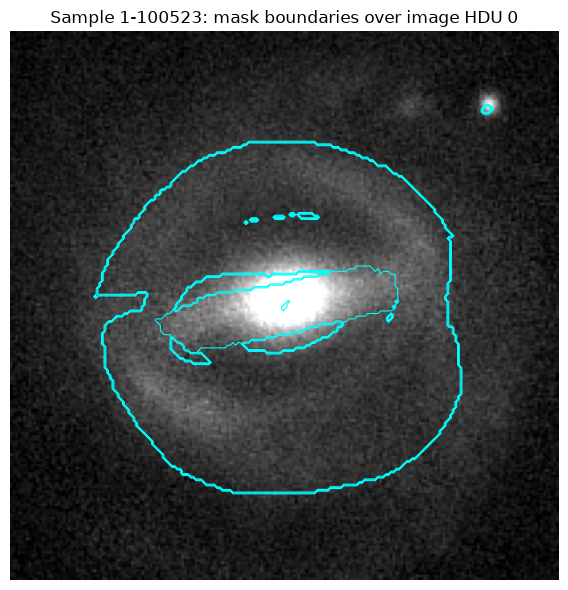

In [7]:
# Overlay boundaries for the distinct raw mask values on the first image HDU.
overlay_index, overlay_name, overlay_image = image_arrays[0]
vmin, vmax = display_limits(overlay_image)
fig, ax = plt.subplots(figsize=(7, 6))
if vmin is not None:
    ax.imshow(np.ma.masked_invalid(overlay_image), origin='lower', cmap='gray', vmin=vmin, vmax=vmax)
if len(raw_values) > 1 and finite_mask.any():
    boundary_levels = np.arange(len(raw_values) - 1) + 0.5
    ax.contour(np.ma.masked_invalid(mask_codes), levels=boundary_levels, colors='cyan', linewidths=0.8)
ax.set_title(f'Sample {REPRESENTATIVE_ID}: mask boundaries over image HDU {overlay_index}')
ax.set_axis_off()
fig.tight_layout()
plt.show()

## 6. Pairing, dimensions, and audit errors

These checks use the saved report rather than scanning the dataset again. Unmatched masks remain visible below. Dimension comparisons for duplicate IDs are candidate comparisons and remain marked ambiguous; they are not treated as unique pairings.

In [ ]:
dimension_checks = audit['dimension_checks']
quality_checks = [
    ('Dimension comparisons', dimension_checks['comparison_count']),
    ('Dimension mismatches', len(dimension_checks['mismatches'])),
    ('Ambiguous duplicate-ID comparisons', len(dimension_checks['ambiguous_candidate_combinations'])),
    ('Dimension checks unavailable', len(dimension_checks['unavailable'])),
    ('File read errors', len(errors.get('file_errors', []))),
    ('HDU inspection errors', len(errors.get('hdu_errors', []))),
]
display(pd.DataFrame(quality_checks, columns=['Check', 'Count']))

unmatched_mask_ids = [item['sample_id'] for item in pairing['unmatched_masks']]
print(f'Unmatched mask IDs ({len(unmatched_mask_ids)}):')
display(pd.DataFrame({'sample_id': unmatched_mask_ids}))
if dimension_checks['mismatches']:
    display(pd.DataFrame(dimension_checks['mismatches']))
if dimension_checks['ambiguous_candidate_combinations']:
    display(pd.DataFrame(dimension_checks['ambiguous_candidate_combinations']))
if errors.get('file_errors') or errors.get('hdu_errors'):
    display(pd.DataFrame(errors.get('file_errors', []) + errors.get('hdu_errors', [])))

## Interpretation boundary

The raw meanings shown here (0 = No relevant data; 1 = galaxy center or core; 2 = galaxy bar; 3 = galaxy arms; 4 = star) come from the official benchmark documentation, not from local frequencies or visual appearance. The separate current project training policy ignores raw 0 with `ignore_index=255` and maps raw 1-4 to training IDs 0-3. The display stretch is visualization-only; it is not preprocessing, and no raw FITS values are changed.
